                  pickup             dropoff  passengers  distance  fare  \
0    2019-03-23 20:21:09 2019-03-23 20:27:24           1      1.60   7.0   
1    2019-03-04 16:11:55 2019-03-04 16:19:00           1      0.79   5.0   
2    2019-03-27 17:53:01 2019-03-27 18:00:25           1      1.37   7.5   
3    2019-03-10 01:23:59 2019-03-10 01:49:51           1      7.70  27.0   
4    2019-03-30 13:27:42 2019-03-30 13:37:14           3      2.16   9.0   
...                  ...                 ...         ...       ...   ...   
6428 2019-03-31 09:51:53 2019-03-31 09:55:27           1      0.75   4.5   
6429 2019-03-31 17:38:00 2019-03-31 18:34:23           1     18.74  58.0   
6430 2019-03-23 22:55:18 2019-03-23 23:14:25           1      4.14  16.0   
6431 2019-03-04 10:09:25 2019-03-04 10:14:29           1      1.12   6.0   
6432 2019-03-13 19:31:22 2019-03-13 19:48:02           1      3.85  15.0   

       tip  tolls  total   color      payment            pickup_zone  \
0     2.15    0

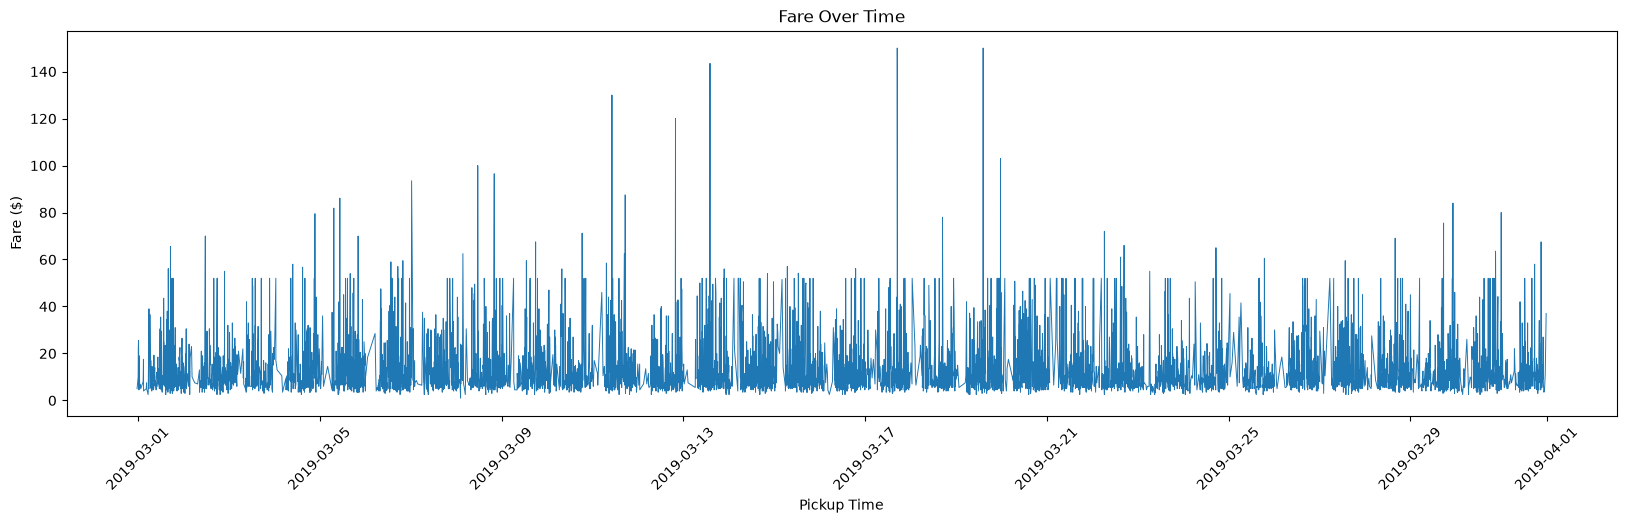

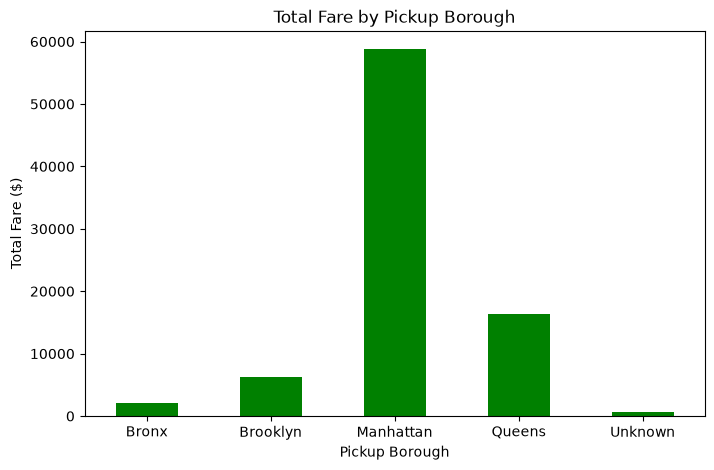

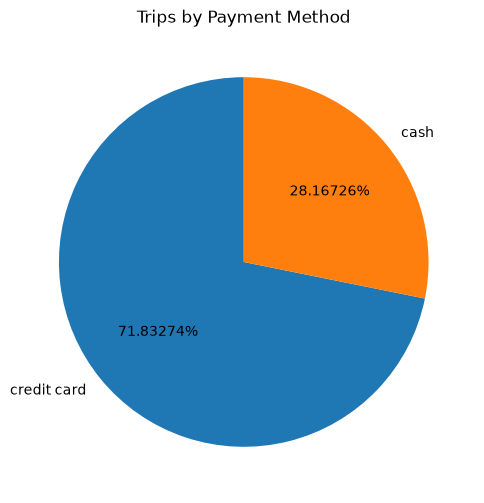

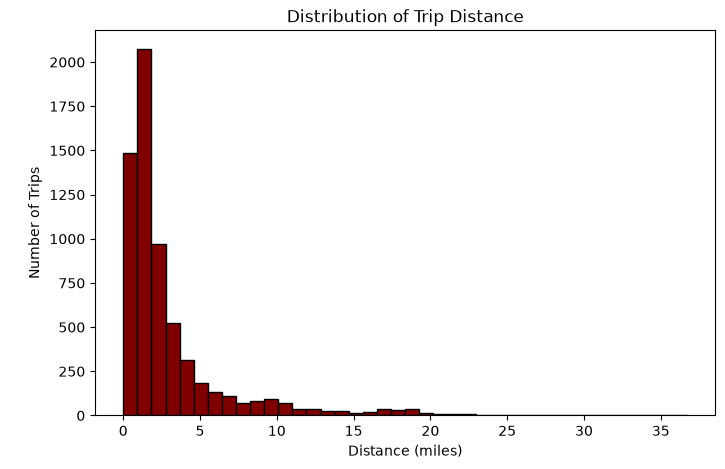

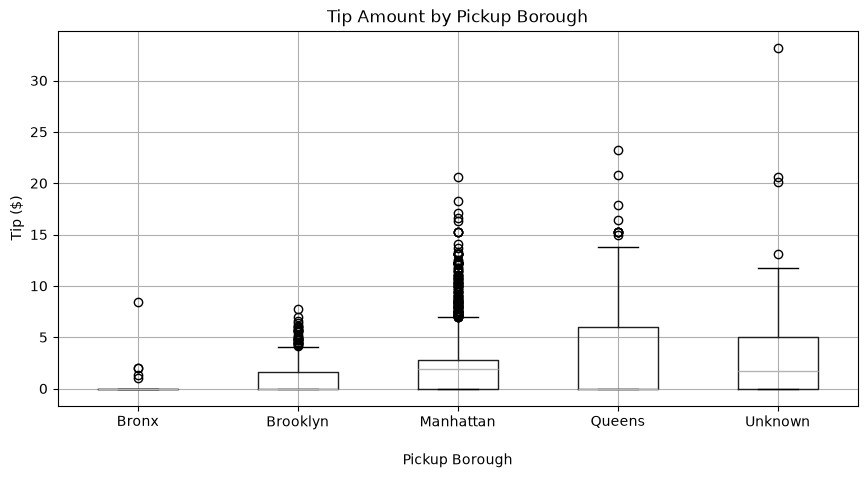

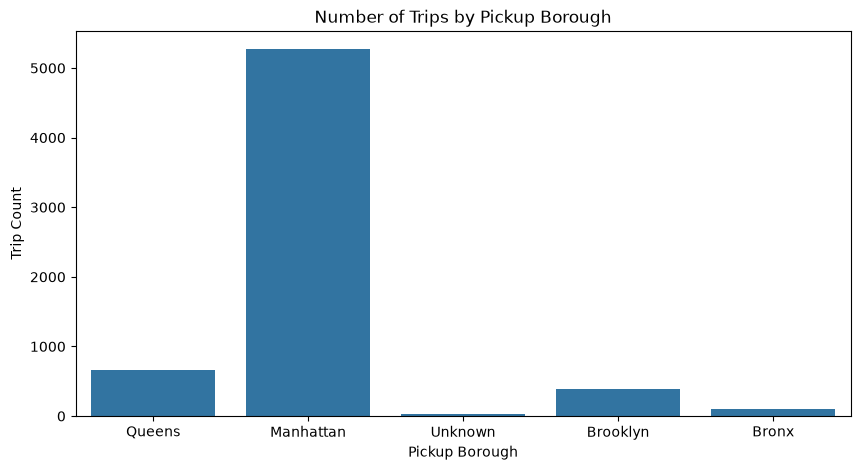

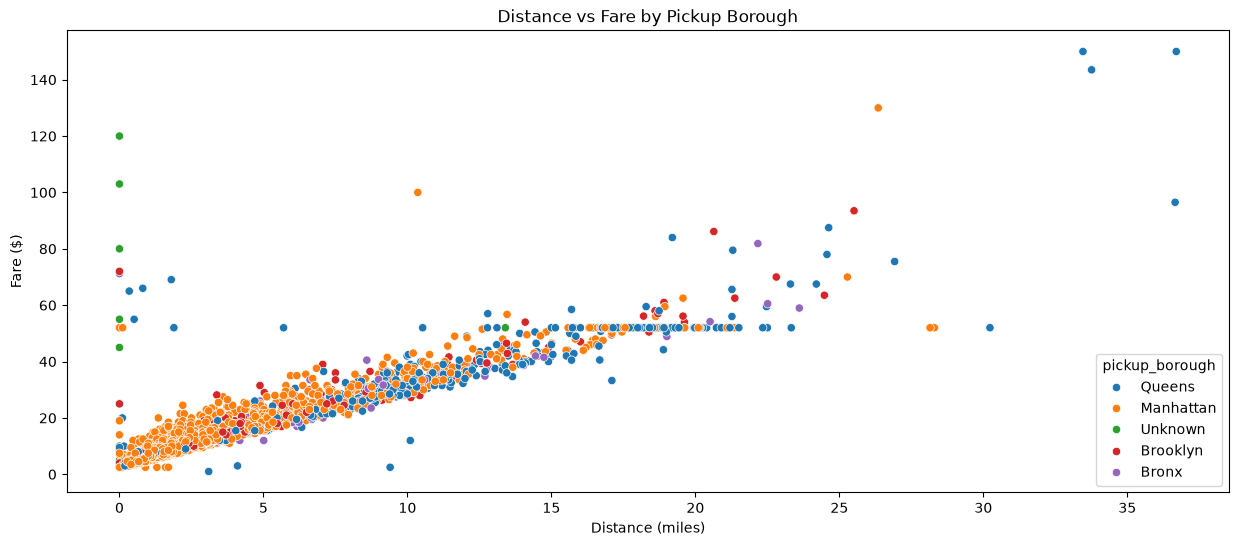

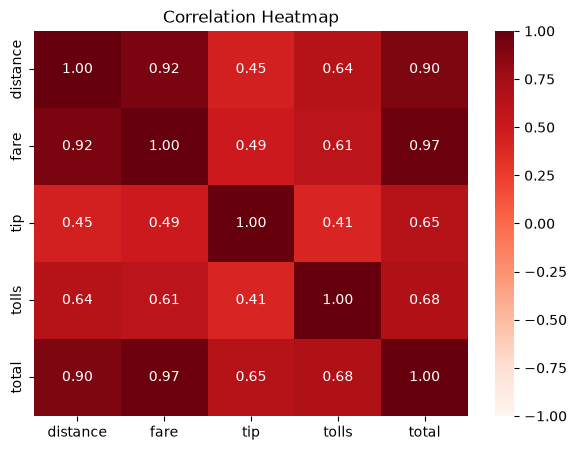

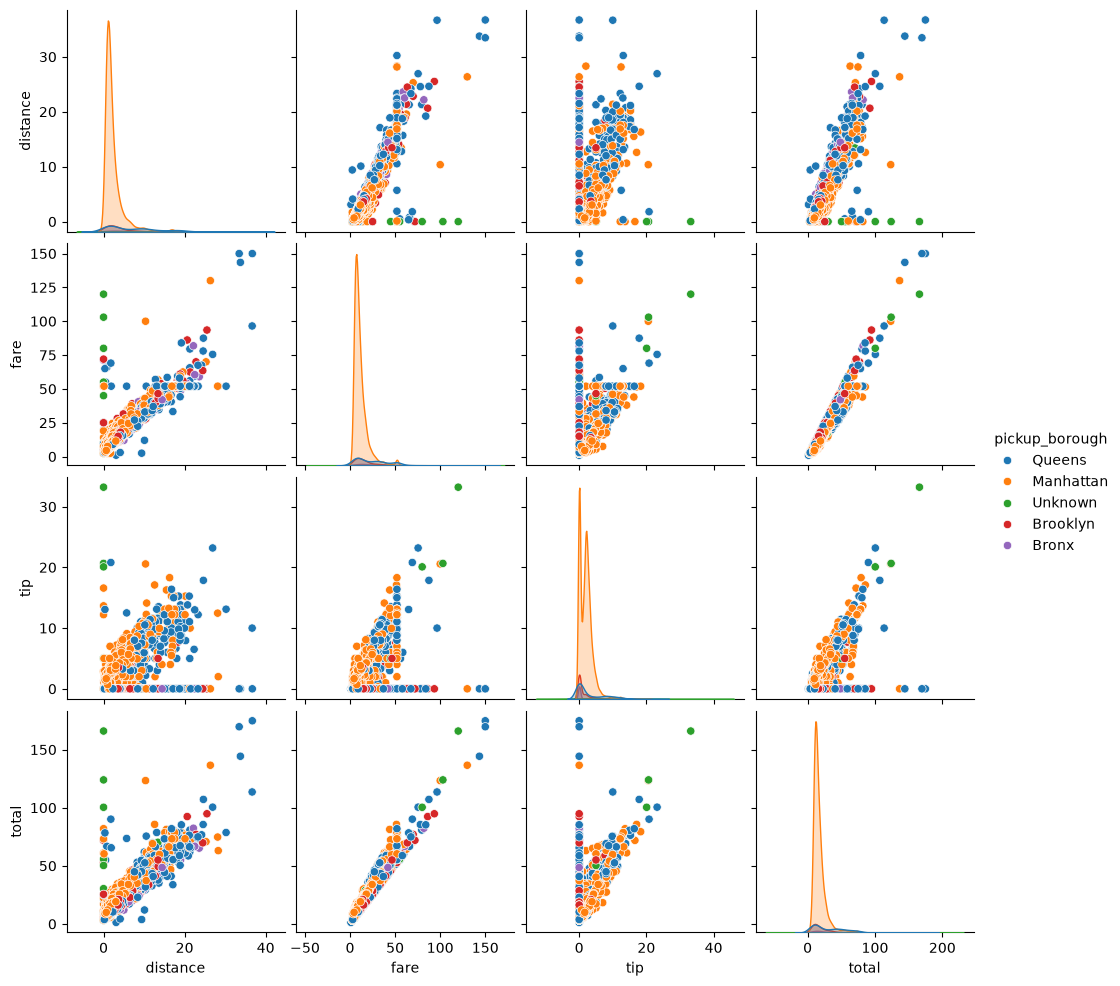

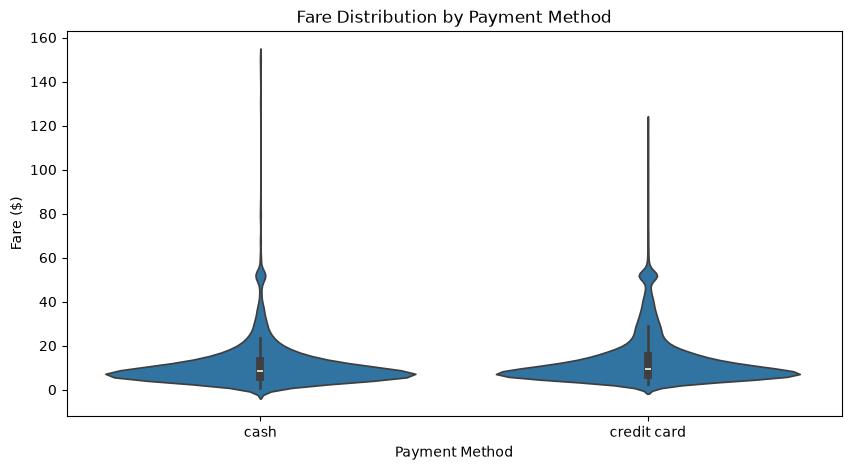

In [28]:
import seaborn as sns 
import pandas as pd
import matplotlib.pyplot as plt

#------------------------------------------------------ Load the 'taxis' dataset------------------------------------------------------------------#
df = sns.load_dataset("taxis")
print(df)

#-------------------------------------------------------Checking missing values--------------------------------------------------------------------#
missing_values=df.isna().sum()
print("\n Number of missing values in each column\n",missing_values)

#Impute missing values

# In Payment method: mode is reasonable because one category clearly dominates
df["payment"] = df["payment"].fillna(df["payment"].mode()[0])

# In case of location columns with missing values label them "Unknown"
for col in ["pickup_zone", "pickup_borough", "dropoff_zone", "dropoff_borough"]:
    df[col] = df[col].fillna("Unknown")


#---------------------------------------------- Visualizations using Matplotlib/Pandas Plot--------------------------------------------------------#

# Line chart: fare over time

# Convert pickup to datetime and sort by time
df["pickup"] = pd.to_datetime(df["pickup"],errors="coerce")
df = df.sort_values("pickup")
plt.figure(figsize=(20, 5))
plt.plot(df["pickup"], df["fare"], linewidth=0.7)
plt.title("Fare Over Time")
plt.xlabel("Pickup Time")
plt.ylabel("Fare ($)")
plt.xticks(rotation=45)
plt.show()
print("\n\n")

#Bar chart: total fare per pickup_borough 
fare_by_pickup_borough = df.groupby("pickup_borough")["fare"].sum()
fare_by_pickup_borough.plot(kind="bar", figsize=(8, 5), color="green")
plt.title("Total Fare by Pickup Borough")
plt.xlabel("Pickup Borough")
plt.ylabel("Total Fare ($)")
plt.xticks(rotation=0)
plt.show()
print("\n\n")

#Pie Chart----Plot a pie chart showing the distribution of trips based on the payment method
df["payment"].value_counts().plot(kind="pie", autopct="%1.5f%%", figsize=(6, 6), startangle=90)
plt.title("Trips by Payment Method")
plt.ylabel("")
plt.show()
print("\n\n")

# Histogram to viusalize distribution of distance
plt.figure(figsize=(8, 5))
plt.hist(df["distance"], bins=40, color="maroon", edgecolor="black")
plt.title("Distribution of Trip Distance")
plt.xlabel("Distance (miles)")
plt.ylabel("\nNumber of Trips")
plt.show()
print("\n\n")

#box plot to visualize the distribution of tip amounts for each pickup_borough
df.boxplot(column="tip", by="pickup_borough", figsize=(10, 5))
plt.title("Tip Amount by Pickup Borough")
plt.suptitle("")
plt.xlabel("\nPickup Borough")
plt.ylabel("Tip ($)")
plt.show()
print("\n\n")

#---------------------------------------------------------Visualizations using Seaborn-------------------------------------------------------------#

# count plot to visualize the number of trips in each pickup_borough

plt.figure(figsize=(10, 5))
sns.countplot(data=df, x="pickup_borough", order=df["pickup_borough"])
plt.title("Number of Trips by Pickup Borough")
plt.xlabel("Pickup Borough")
plt.ylabel("Trip Count")
plt.show()
print("\n\n")

#Scatter plot to show the relationship between distance and fare

# Scatter plot: distance vs fare, colored by pickup borough
plt.figure(figsize=(15, 6))
sns.scatterplot(data=df, x="distance", y="fare", hue="pickup_borough", alpha=1.0)
plt.title("Distance vs Fare by Pickup Borough")
plt.xlabel("Distance (miles)")
plt.ylabel("Fare ($)")
plt.show()
print("\n\n")

# Heatmap to visualize the correlation between numerical variables such as distance, fare, tip, tolls, and total
plt.figure(figsize=(7, 5))
sns.heatmap(df[["distance", "fare", "tip", "tolls", "total"]].corr(), annot=True, cmap="Reds", fmt=".2f", vmin=-1, vmax=1)
plt.title("Correlation Heatmap")
plt.show()
print("\n\n")

# pair plot to visualize the pairwise relationships between distance, fare, tip and total colored by pickup_borough

sns.pairplot(df[["distance", "fare", "tip", "total", "pickup_borough"]],hue="pickup_borough")
plt.show()
print("\n\n")

#violin plot to show the distribution of fare for each payment method using the payment method as the categorical axis and fare as the numeric axis
plt.figure(figsize=(10, 5))
sns.violinplot(data=df, x="payment", y="fare")
plt.title("Fare Distribution by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Fare ($)")
plt.show()


